# Valuation framework

One company, valued in the order an analyst does it, with every formula printed with its numbers:

1. **Historic performance** and earnings quality
2. **Future cash flows** (FCFF for operating companies, excess returns for banks and insurers, dividends for REITs)
3. **Discount rate**: 10-year yield, market return, MRP, beta regressed on daily returns, cost of equity, WACC
4. **Discount** the cash flows and add the terminal value
5. **Enterprise value → equity value (market cap) → ÷ shares → fair price**
6. **Verdict**: DCF, Monte Carlo, comps and the peer regression blended into a call and an expected alpha

Set the company in the next cell. Your own numbers go in `OVERRIDES`; every override is shown next to the pulled value it replaced. The last cell writes the same valuation as a live-formula Excel workbook.

In [1]:
# ---- settings -----------------------------------------------------------
TICKER = "SNDK"        # any ticker Yahoo covers
SNAPSHOT = "tests/fixtures/sndk_yahoo_2026-10-20.json"       # path to a saved snapshot (TICKER_yahoo_YYYY-MM-DD.json) to rerun on the same data; None = pull live
INPUTS = None          # path to a hand-built inputs file (e.g. dell_inputs.json, a segment model); overrides TICKER
PEERS = None           # e.g. ["HPQ", "HPE", "SMCI"]; None = Yahoo's related symbols (check them)
SCENARIO = "Base"      # Bear, Base or Bull
OVERRIDES = {}

In [2]:
import framework as fw
import pandas as pd
from IPython.display import display
pd.options.display.float_format = "{:,.4f}".format

inp = fw.load(ticker=TICKER, snapshot=SNAPSHOT, inputs=INPUTS, peers=PEERS)
inp, changes = fw.override(inp, OVERRIDES)
if len(changes):
    display(changes)
ok, lines = fw.checks(inp)
fw.say(lines)

Model: FCFF DCF (operating company)  ·  Sandisk Corporation (SNDK)  ·  price $1,365.38
  ! [scenarios.Bear.margins.total.1] Worst annual margin -21.3% is a loss; Bear fades to the 4-year average 10.1% instead
  ! [scenarios.Base.margins.total.0] Consensus EPS implies a 77.6% operating margin next year against 61.6% trailing; Base year 1 uses consensus
  ! [relative.weights] Latest quarter annualised is 1.77x trailing revenue; trailing EV/EBITDA and EV/Sales understate the business, so comps use forward P/E only


## Scenario switch
Bear / Base / Bull side by side, then toggle a case: steps 2–6 re-run for it below the buttons. (The step-by-step cells further down use `SCENARIO` from the settings cell.)

In [3]:
fw.scenario_switch(inp)

,Bear,Base,Bull
"Revenue growth, year 2",13.9%,18.9%,22.9%
"EBIT margin, year 1 → year 5",61.6% → 10.1%,77.6% → 35.9%,77.6% → 61.6%
"FCFF, year 1 ($m)","24,008","30,909","30,909"
Enterprise value ($m),"93,004","224,976","363,590"
Terminal value share,16%,28%,33%
Value per share,$627.47,"$1,476.02","$2,367.26"
vs price,-54.0%,8.1%,73.4%


## Step 1 · Historic performance
Reported history ($m). Growth and margins are computed from the reported lines.

In [4]:
display(fw.fmt(fw.step1_history(inp)))

,FY23,FY24,FY25,FY26
Revenue,"6,086","6,663","7,355","20,248"
Operating income,"-1,295",-444,507,"12,468"
Net income,"-2,143",-672,"-1,641","11,433"
Diluted EPS,-15,-5,-11,—
Cash from operations,-713,-309,84,"11,671"
Capex,219,166,204,177
Free cash flow,-932,-475,-120,"11,494"
Revenue growth,—,9.5%,10.4%,175.3%
Operating income ÷ revenue,-0,-0,0,1
Net income ÷ revenue,-0,-0,-0,1


### Earnings quality
Are the earnings backed by cash? Beneish M-score, Sloan accruals, cash conversion. Grade D withholds the call; C marks it low confidence.

In [5]:
E, beneish, lines = fw.step1_quality(inp)
display(beneish.round(3))
fw.say(lines)

,FY24,FY25,FY26,coefficient,manipulators' mean
DSRI,NaN,1.0350,1.6010,0.9200,1.4650
GMI,0.4390,0.5350,0.4210,0.5280,1.1930
AQI,NaN,0.8260,0.7170,0.4040,1.2540
SGI,1.0950,1.1040,2.7530,0.8920,1.6070
DEPI,NaN,1.0590,1.1510,0.1150,1.0770
SGAI,0.7450,1.1410,0.4290,-0.1720,1.0410
LVGI,NaN,NaN,NaN,-0.3270,1.1110
TATA,-0.0270,-0.1330,-0.0110,4.6790,0.0310
M-score,NaN,-3.3100,-0.7170,-4.8400,NaN


Earnings-quality grade: C
M = −4.84 + 0.92×1.601 + 0.528×0.421 + 0.404×0.717 + 0.892×2.753 + 0.115×1.151 − 0.172×0.429 − 0.327×1.000 + 4.679×-0.011 = -0.72   (red above −1.78, amber above −2.22)
Accruals = (net income − operating cash flow) ÷ average assets = -1.3%   (red above 10%, amber above 5%)
Cash conversion = Σ operating cash flow ÷ Σ net income, 3 years = 126%   (red below 50%, amber below 80%)
  RED: Beneish M-score -0.72 is above −1.78, the level Beneish found for likely manipulators
  INFO: M-score inputs missing (LVGI): set to 1, which is neutral


## Step 2 · Future cash flows
Scenario drivers first (with where the Base values came from), then the forecast.

In [6]:
display(fw.drivers(inp))
cash_flows, lines = fw.step2_cash_flows(inp, SCENARIO)
display(fw.fmt(cash_flows, per_share=inp.get("model") == "ddm"))
fw.say(lines)

scenario,Bear,Base,Bull,Base comes from
driver,,,,
growth.total.0,0.1393,0.1893,0.2293,sourced consensus: FY28 ÷ FY27 revenue estimat...
growth.total.1,0.1145,0.1520,0.1820,"assumption fade: g×0.75+1%, g×0.5+1.5%, g×0.35+2%"
growth.total.2,0.0846,0.1096,0.1296,"assumption fade: g×0.75+1%, g×0.5+1.5%, g×0.35+2%"
growth.total.3,0.0688,0.0863,0.1003,"assumption fade: g×0.75+1%, g×0.5+1.5%, g×0.35+2%"
margins.total.0,0.6158,0.7757,0.7757,derived Yahoo Finance quoteSummary consensus F...
margins.total.1,0.1013,0.3585,0.6158,assumption midpoint of TTM and multi-year aver...


,FY27,FY28,FY29,FY30,FY31,FY32,FY33,FY34,FY35,FY36
Revenue,"49,135","58,436","67,316","74,697","81,140","87,226","92,786","97,658","101,686","104,737"
Growth,142.7%,18.9%,15.2%,11.0%,8.6%,7.5%,6.4%,5.3%,4.1%,3.0%
EBIT,"38,113","39,233","38,176","34,572","29,092","31,274","33,268","35,014","36,459","37,553"
EBIT margin,77.6%,67.1%,56.7%,46.3%,35.9%,35.9%,35.9%,35.9%,35.9%,35.9%
Tax rate,12.2%,13.6%,15.1%,16.5%,18.0%,18.0%,18.0%,18.0%,18.0%,18.0%
NOPAT,"33,475","33,887","32,417","28,853","23,856","25,645","27,280","28,712","29,896","30,793"
+ D&A,769,914,"1,053","1,168","1,269","1,364","1,451","1,528","1,591","1,638"
− Capex,784,933,"1,075","1,192","1,295","1,392","1,481","1,559","1,623","1,672"
− ΔNWC,"2,551","1,787","1,706","1,418","1,238","1,169","1,068",936,774,586
FCFF,"30,909","32,081","30,689","27,411","22,592","24,447","26,181","27,744","29,090","30,173"


Year 1 (FY27), Base case:
  Revenue = 49,135 (consensus or segment build); EBIT = Σ segment revenue × margin − corporate = 38,113 (77.6%)
  NOPAT = EBIT × (1 − tax) = 38,113 × (1 − 12.2%) = 33,475
  FCFF = NOPAT + D&A − capex − ΔNWC = 33,475 + 769 − 784 − 2,551 = 30,909
  D&A 1.56% and capex 1.60% of revenue; ΔNWC = 19.21% × change in revenue (year 1: 19.21% × 49,135 − opening NWC 6,890)
  Growth after year 5 fades in a straight line to terminal g 3.00%; margins move from year 1 to the long-run level by year 5


## Step 3 · Discount rate
Cost of equity = rf + β × (Rm − rf), with β regressed on daily returns against the S&P 500.

Cost of equity (CAPM):
  1  Risk-free rate rf = 10-year Treasury = 5.12%
  2  Expected market return Rm = 9.35%
  3  Market risk premium = Rm − rf = 9.35% − 5.12% = 4.23%
  4a Daily regression: stock return = α + β × S&P 500 return, 422 days 2025-02-13 to 2026-10-20
     β = 2.8511  (s.e. 0.2728, t 10.5, R² 0.206, 95% CI 2.32–3.39)
  4b β used = 2.2403 (Blume-adjusted daily β = 0.67 × β + 0.33)
  5  Equity risk premium for this stock = β × MRP = 2.2403 × 4.23% = 9.48%
  6  Ke = rf + β × MRP + CRP = 5.12% + 9.48% + 0.00% = 14.59%
Cost of capital:
  Kd after tax = 5.71% × (1 − 21%) = 4.51%   (rf + AAA spread, coverage 170.8x)
  E = price × diluted shares = 212,354; D = debt + leases = 177
  WACC = E/(D+E) × Ke + D/(D+E) × Kd(1−t) = 99.9% × 14.59% + 0.1% × 4.51% = 14.58%


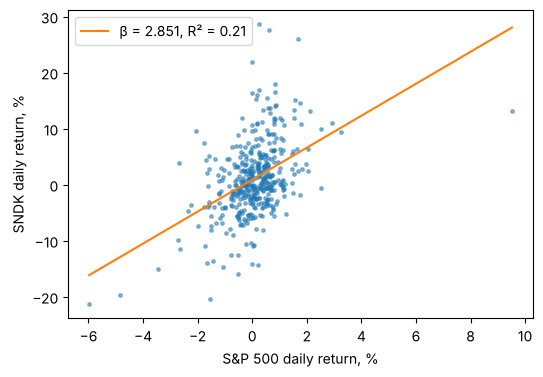

In [7]:
W, beta_stats, lines = fw.step3_discount_rate(inp)
fw.say(lines)
fw.beta_plot(inp);

## Step 4 · Discount the cash flows
PV = cash flow × (1 + r)^−t, then the terminal value.

In [8]:
d, disc, lines = fw.step4_discount(inp, SCENARIO)
display(fw.fmt(disc, per_share=inp.get("model") == "ddm"))
fw.say(lines)

,FY27,FY28,FY29,FY30,FY31,FY32,FY33,FY34,FY35,FY36
Counted,"30,909","32,081","30,689","27,411","22,592","24,447","26,181","27,744","29,090","30,173"
Share of year,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
t (years),0.2009,1.2009,2.2009,3.2009,4.2009,5.2009,6.2009,7.2009,8.2009,9.2009
Discount factor (1+r)^−t,0.9730,0.8492,0.7411,0.6468,0.5644,0.4926,0.4299,0.3752,0.3274,0.2857
Present value,"30,075","27,243","22,743","17,728","12,751","12,043","11,255","10,409","9,524","8,622"


Discount rate r = 14.58% (WACC); mid-year discounting; first year counts 100%
  Σ PV FY27–FY36 = 162,393
  Terminal value = NOPAT × (1 + g) × (1 − g/RONIC) ÷ (WACC − g) = 30,793 × 1.030 × (1 − 3.0%/15%) ÷ (14.58% − 3.0%) = 219,021
  PV of terminal value = 62,584 (28% of EV)   · exit-multiple check 12.0x EBITDA → $1,880.80 a share
  Enterprise value = Σ PV + PV terminal = 162,393 + 62,584 = 224,976


## Step 5 · From value to the share price

In [9]:
bridge, lines = fw.step5_price(inp, SCENARIO)
display(bridge.style.format("{:,.2f}"))
fw.say(lines)

,value
step,
Enterprise value,"224,976.43"
− Debt (ex leases),-0.00
− Leases,-177.00
+ Cash,"4,762.00"
+ Captive-finance net assets,0.00
+ Investments,0.00
− Non-controlling interests,-0.00
= Equity value (market cap),"229,561.43"


Fair price = equity value ÷ diluted shares = 229,561 ÷ 155.53 = $1,476.02
Price today $1,365.38 → 8.1% (Base case, FCFF DCF alone)


## Step 6 · Verdict
The absolute model, Monte Carlo, comps and the peer regression, blended by weight.

,value / share,weight,vs price
method,,,
FCFF DCF,"$1,476.02",40%,+8.1%
Monte Carlo median,"$1,452.30",20%,+6.4%
Comps blend,"$1,153.35",30%,-15.5%
Peer regression,$883.02,10%,-35.3%


,k,n,q1,q3,min,max,own,premium,implied,impliedQ1,impliedQ3,weight,usable
pe_fwd,4.3311,5,2.9178,10.9487,2.6146,11.8476,5.1273,0.1838,"1,153.3493",776.9962,"2,915.6068",1,True


Blended fair value = Σ weight × value ÷ Σ weight = $1,315.17  vs price $1,365.38 → -3.7%
Call (±10% band): FAIRLY VALUED  · low confidence (earnings quality C)
Expected 1-year return = (fair ÷ price)^(1/1) − 1 + dividend yield 0.00% = -3.7%
Required return Ke = 14.59% → expected alpha = -18.3%
Monte Carlo: 5,000 runs, P(value > price) = 70%, p10–p90 $1,253.29–$1,683.80
  ! Worst annual margin -21.3% is a loss; Bear fades to the 4-year average 10.1% instead
  ! Consensus EPS implies a 77.6% operating margin next year against 61.6% trailing; Base year 1 uses consensus
  ! Latest quarter annualised is 1.77x trailing revenue; trailing EV/EBITDA and EV/Sales understate the business, so comps use forward P/E only
  ! Earnings quality C: Beneish M-score -0.72 is above −1.78, the level Beneish found for likely manipulators


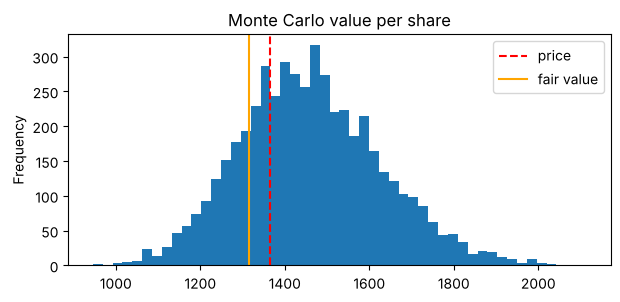

In [10]:
R, methods, comps, lines = fw.step6_verdict(inp, SCENARIO)
display(methods.style.format({"value / share": "${:,.2f}", "weight": "{:.0%}", "vs price": "{:+.1%}"}, na_rep="—"))
display(comps)
fw.say(lines)
import matplotlib.pyplot as plt
ax = pd.Series(R["mc"]["values"]).plot.hist(bins=50, figsize=(7, 3), title="Monte Carlo value per share")
ax.axvline(inp["market"]["price"], color="red", ls="--", label="price"); ax.axvline(R["verdict"]["fair"], color="orange", label="fair value"); ax.legend();

### Sensitivity and what the price implies

In [11]:
grid, lines = fw.sensitivity(inp, SCENARIO)
display(grid.style.format("${:,.2f}", na_rep="—"))
fw.say(lines)

terminal g,2.0%,2.5%,3.0%,3.5%,4.0%
WACC,,,,,
12.58%,"$1,677.28","$1,694.54","$1,712.72","$1,731.93","$1,752.33"
13.58%,"$1,557.78","$1,570.47","$1,583.62","$1,597.27","$1,611.49"
14.58%,"$1,456.84","$1,466.34","$1,476.02","$1,485.90","$1,496.00"
15.58%,"$1,370.40","$1,377.60","$1,384.84","$1,392.11","$1,399.40"
16.58%,"$1,295.49","$1,301.03","$1,306.51","$1,311.94","$1,317.27"


Reverse: the price $1,365.38 implies a discount rate of 15.82% (model 14.58%)


## Sources
Every input with its origin: **sourced** (read from a filing or feed), **derived** (computed from sourced numbers; formula given) or **assumption** (a modelling choice; change it in `OVERRIDES`).

In [12]:
display(fw.sources(inp))

,input,value,origin,source / basis
0,bridge.cash,"4,762.0000",sourced,Yahoo Finance fundamentals (quarterly) CashAnd...
1,bridge.core_debt,0.0000,sourced,Yahoo Finance fundamentals (quarterly) TotalDe...
2,bridge.investments,0,assumption,not in feed; enter from the 10-K
3,bridge.leases,177.0000,sourced,Yahoo Finance fundamentals (quarterly) Capital...
4,bridge.nci,0.0000,sourced,Yahoo Finance fundamentals (quarterly) Minorit...
...,...,...,...,...
61,verdict.weights.comps,0.3000,assumption,method weights
62,verdict.weights.dcf,0.4000,assumption,method weights
63,verdict.weights.mc,0.2000,assumption,method weights
64,verdict.weights.regression,0.1000,assumption,method weights


## Export
The same valuation as an Excel workbook in which every step is a live formula, and the inputs file the terminal can load.

In [13]:
import json
xlsx = fw.export_excel(inp, f"{inp['meta']['ticker']}_valuation.xlsx", SCENARIO)
json.dump(inp, open(f"{inp['meta']['ticker']}_inputs.json", "w"), indent=1)
print("wrote", xlsx, "and", f"{inp['meta']['ticker']}_inputs.json")

wrote SNDK_valuation.xlsx and SNDK_inputs.json
